In [10]:
import pandas as pd

# 1. Définition des 26 colonnes (Dictionnaire de données)
colonnes = ['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3'] + [f'sensor_{i}' for i in range(1, 22)]

# 2. Lecture du fichier texte
# sep='\s+' signifie que les colonnes sont séparées par un ou plusieurs espaces
chemin_fichier = '../data/train_FD001.txt'
df = pd.read_csv(chemin_fichier, sep='\s+', names=colonnes)

# 3. Affichage des 5 premières lignes
df.head(15)

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
5,1,6,-0.0043,-0.0001,100.0,518.67,642.10,1584.47,1398.37,14.62,...,521.68,2388.03,8132.85,8.4108,0.03,391,2388,100.0,38.98,23.3669
6,1,7,0.0010,0.0001,100.0,518.67,642.48,1592.32,1397.77,14.62,...,522.32,2388.03,8132.32,8.3974,0.03,392,2388,100.0,39.10,23.3774
7,1,8,-0.0034,0.0003,100.0,518.67,642.56,1582.96,1400.97,14.62,...,522.47,2388.03,8131.07,8.4076,0.03,391,2388,100.0,38.97,23.3106
8,1,9,0.0008,0.0001,100.0,518.67,642.12,1590.98,1394.80,14.62,...,521.79,2388.05,8125.69,8.3728,0.03,392,2388,100.0,39.05,23.4066
9,1,10,-0.0033,0.0001,100.0,518.67,641.71,1591.24,1400.46,14.62,...,521.79,2388.06,8129.38,8.4286,0.03,393,2388,100.0,38.95,23.4694


In [11]:
# 1. Trouver le dernier cycle de vol (le moment de la panne) pour chaque moteur
rul_max = df.groupby('engine_id')['cycle'].max().reset_index()
rul_max.columns = ['engine_id', 'max_cycle']

# 2. Joindre cette information au tableau principal
df = df.merge(rul_max, on='engine_id', how='left')

# 3. Calculer la RUL (Cycle max - Cycle actuel)
df['RUL'] = df['max_cycle'] - df['cycle']

# 4. Nettoyer en supprimant la colonne intermédiaire
df.drop(columns=['max_cycle'], inplace=True)

# Afficher les premières lignes pour vérifier
df[['engine_id', 'cycle', 'RUL']].head()

,engine_id,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


In [12]:
colonnes_constantes = [col for col in df.columns if df[col].nunique() == 1]
df.drop(columns=colonnes_constantes, inplace=True)

print(f"Colonnes supprimées : {colonnes_constantes}")
print(f"Nouvelle taille du dataset : {df.shape}\n")

Colonnes supprimées : ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Nouvelle taille du dataset : (20631, 20)



In [13]:
!pip install matplotlib seaborn

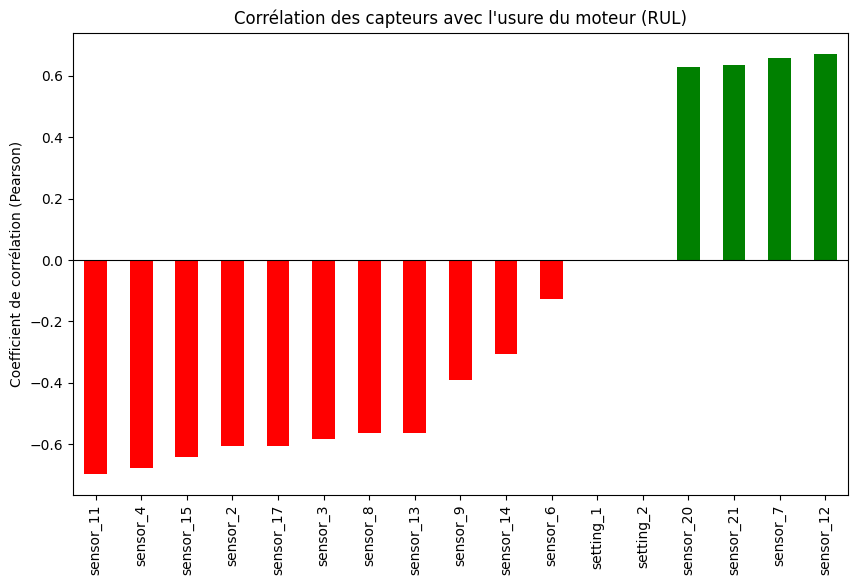

In [14]:
#  Affichage : Calculer et visualiser la corrélation des capteurs avec la RUL
import matplotlib.pyplot as plt
import seaborn as sns

corr_matrix = df.corr()
rul_corr = corr_matrix['RUL'].drop(['RUL', 'engine_id', 'cycle']).sort_values()

plt.figure(figsize=(10, 6))
rul_corr.plot(kind='bar', color=rul_corr.map(lambda x: 'red' if x < 0 else 'green'))
plt.title('Corrélation des capteurs avec l\'usure du moteur (RUL)')
plt.ylabel('Coefficient de corrélation (Pearson)')
plt.axhline(0, color='black', linewidth=0.8)
plt.show()